# Where should a sick person go? A data story about Kenya's health system

**Healthcare Access Optimization System: data exploration and analysis**
Maina Linet Muthoni | KCA University, School of Technology | BSc Data Science

I built a system that takes a person's symptoms, suggests a level of care (KEPH levels 2 to 6) and points them to nearby facilities.
Before trusting any model, I wanted to know three things:

1. **Can I trust the data?** Is 4,920 rows really 4,920 patients?
2. **What does Kenya actually have?** How many facilities can give each level of care, and where are they?
3. **Does the model fail in a way that matters?** Not "how many diseases did it get wrong" but "how many people would it send to the wrong level".

Each chart has its finding as the title. The numbers quoted in the text come from running this notebook on the project data, so if you change the data, re-run it (**Kernel > Restart & Run All**) and check the text against the new output.

## Before we start

This notebook only reads the project files: the two symptom datasets in `data/`, the facility database in `backend/`, the trained model in `ML/` and the evaluation results in `ML/evaluation/`. It needs `numpy`, `pandas`, `matplotlib`, `scikit-learn` and `joblib`, all of which the project already uses. It finds the project folder by itself, so it runs from the repo root or from `notebook/`.

In [1]:
import sys, json, sqlite3, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import joblib
warnings.filterwarnings("ignore")

# Find the project root whether the notebook is opened from the repo root or from notebook/
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "backend" / "database.sqlite").exists())
sys.path.insert(0, str(ROOT / "ML"))
from train_model import load_raw_rows, vectorize, manual_train_test_split, load_keph_mapping

# One small palette used everywhere, so the charts read as one story
PAPER, INK, SOFT = "#F4F6F5", "#1B2433", "#5B6577"
COBALT, DEEP, LIGHT, GOLD, RED, GREY = "#1D4FB8", "#12306E", "#AEC8F7", "#FFD84D", "#C8372D", "#C9CED8"
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
                     "text.color": INK, "axes.labelcolor": SOFT, "xtick.color": SOFT, "ytick.color": SOFT,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
                     "axes.edgecolor": GREY, "axes.grid": False, "font.size": 10, "font.family": "DejaVu Sans"})

import textwrap
cap = lambda t: t[:1].upper() + t[1:]

def story(fig, title, sub=None):
    """Put the finding itself at the top of the chart, left-aligned, like a newspaper headline.
    Positions are in inches, so the headline sits the same way on tall and short charts."""
    W, H = fig.get_size_inches()
    t = textwrap.fill(title, int(W * 7.4)); n_t = t.count("\n") + 1
    fig.text(0.015, 1 - 0.12 / H, t, ha="left", va="top", fontsize=14, fontweight="bold", color=INK, linespacing=1.15)
    if sub:
        fig.text(0.015, 1 - (0.12 + 0.30 * n_t + 0.10) / H, textwrap.fill(sub, int(W * 12.5)), ha="left", va="top", fontsize=9.5, color=SOFT)

print("Project folder:", ROOT.name)

Project folder: healthcare-access-optimization-system


# Chapter 1. Can I trust the data?

## Two datasets

The project uses two symptom datasets. The **raw** one is the public Kaggle "Disease Symptom Prediction" data. The **augmented** one is built from it for training: it adds realistic noise and overlap, and has 150 rows per disease instead of 120.

In [2]:
raw_header, raw_rows = load_raw_rows(ROOT / "data" / "dataset_real_kaggle_raw.csv")
aug_header, aug_rows = load_raw_rows(ROOT / "data" / "dataset.csv")
symptom_set = lambda row: frozenset(c.strip() for c in row[1:] if c.strip())

raw = pd.DataFrame({"disease": [r[0].strip() for r in raw_rows], "symptoms": [symptom_set(r) for r in raw_rows]})
aug = pd.DataFrame({"disease": [r[0].strip() for r in aug_rows], "symptoms": [symptom_set(r) for r in aug_rows]})
for d in (raw, aug):
    d["n_symptoms"] = d.symptoms.map(len)
    d["case"] = list(zip(d.disease, d.symptoms.map(lambda s: tuple(sorted(s)))))

print(f"Raw Kaggle dataset : {len(raw):,} rows, {raw.disease.nunique()} diseases")
print(f"Augmented dataset  : {len(aug):,} rows, {aug.disease.nunique()} diseases")

Raw Kaggle dataset : 4,920 rows, 41 diseases
Augmented dataset  : 6,150 rows, 41 diseases


## Four thousand patients who are really three hundred

The raw data has 4,920 rows, which sounds like a lot of patients. It isn't. Once I count rows that have the same disease **and** the same symptoms as one case, only **304** are different. The data repeats each case about 16 times, and every disease has only 5 to 10 distinct cases.

This is the single most important thing I found, because it changes how every accuracy number should be read. If you split the rows randomly into training and test sets, copies of the same case land on both sides, and the model gets marked on cases it has already seen. This is why published scores on this dataset are often close to 100%. On distinct cases only, the picture changes a lot, and chapter 5 deals with what that means for the model.

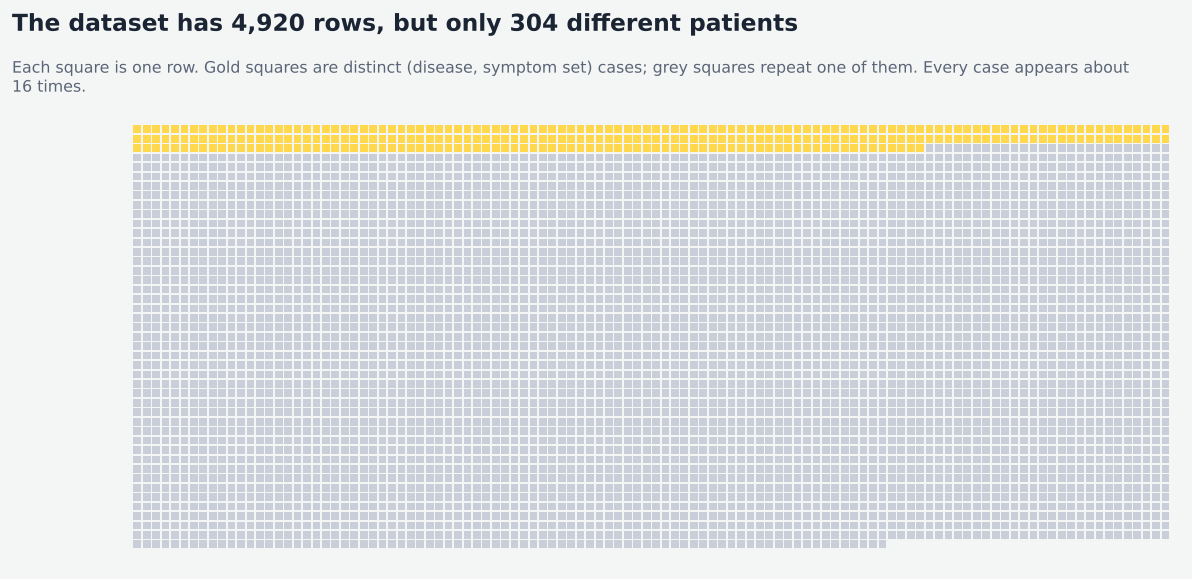

Distinct cases per disease: min 5, median 7, max 10


In [3]:
n_raw, n_unique = len(raw), raw.case.nunique()
per_disease = raw.drop_duplicates("case").groupby("disease").size()

# One square per row of the raw dataset. Gold squares are the cases that are genuinely different.
cols = 110; rows_n = int(np.ceil(n_raw / cols))
fig, ax = plt.subplots(figsize=(11, 4.9)); fig.subplots_adjust(top=0.80, bottom=0.03, left=0.02, right=0.98)
for i in range(n_raw):
    r_, c_ = divmod(i, cols)
    ax.add_patch(Rectangle((c_, -r_), 0.82, 0.82, color=GOLD if i < n_unique else GREY, lw=0))
ax.set_xlim(-1, cols + 1); ax.set_ylim(-rows_n - 1, 2); ax.axis("off"); ax.set_aspect("equal")
story(fig, f"The dataset has {n_raw:,} rows, but only {n_unique} different patients",
      f"Each square is one row. Gold squares are distinct (disease, symptom set) cases; grey squares repeat one of them. "
      f"Every case appears about {n_raw/n_unique:.0f} times.")
plt.show()
print(f"Distinct cases per disease: min {per_disease.min()}, median {per_disease.median():.0f}, max {per_disease.max()}")

## Balance

Every disease has exactly the same number of rows (120 raw, 150 augmented). That removes the usual class-imbalance problem, but it also tells me the data was curated, not collected from clinics. Real clinics see far more malaria and colds than AIDS or paralysis.

In [4]:
bal = pd.DataFrame({"Raw": raw.disease.value_counts(), "Augmented": aug.disease.value_counts()})
print(f"Rows per disease  raw: {bal.Raw.min()}-{bal.Raw.max()}   augmented: {bal.Augmented.min()}-{bal.Augmented.max()}")
print("Perfectly balanced classes:", bal.Raw.nunique() == 1 and bal.Augmented.nunique() == 1,
      "(this also tells us the data is curated, not collected from real clinics)")

Rows per disease  raw: 120-120   augmented: 150-150
Perfectly balanced classes: True (this also tells us the data is curated, not collected from real clinics)


## How much does a patient tell us?

In the raw data a case lists about seven symptoms. In real life, someone typing into a phone will name two or three. Only 7% of the raw cases are that short, against 21% of the augmented ones. The augmentation was meant to close that gap, so the model learns from the kind of short, incomplete symptom lists people actually give.

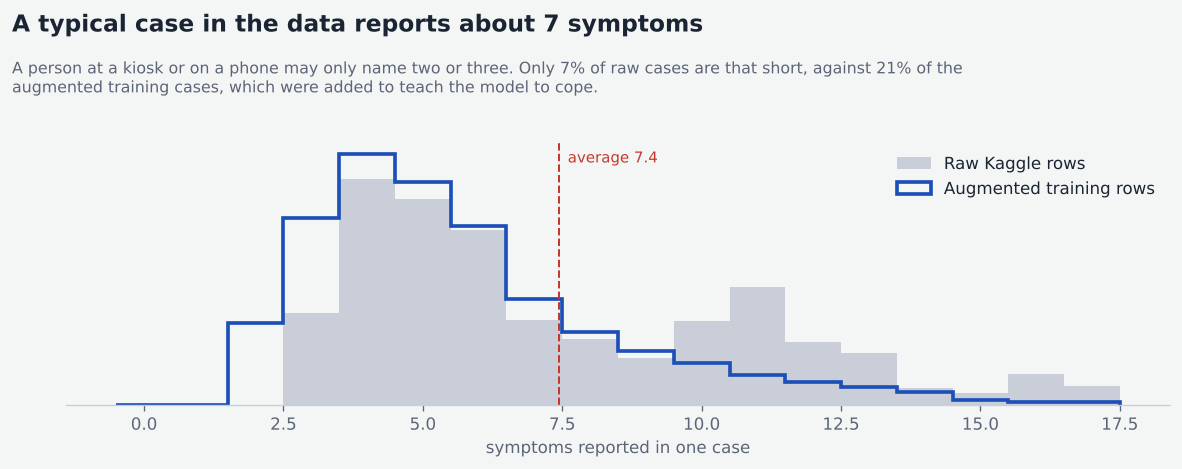

share of raw cases with 3 or fewer symptoms : 7.1%
share of augmented cases with 3 or fewer     : 20.7%


In [5]:
fig, ax = plt.subplots(figsize=(10, 4)); fig.subplots_adjust(top=0.70, bottom=0.15, left=0.06, right=0.98)
bins = np.arange(0, 19) - 0.5
ax.hist(raw.n_symptoms, bins=bins, color=GREY, label="Raw Kaggle rows", density=True)
ax.hist(aug.n_symptoms, bins=bins, histtype="step", color=COBALT, lw=2.2, label="Augmented training rows", density=True)
ax.set_xlabel("symptoms reported in one case"); ax.set_yticks([]); ax.set_ylabel("")
ax.legend(frameon=False, loc="upper right")
ax.axvline(raw.n_symptoms.mean(), color=RED, ls="--", lw=1.2)
ax.text(raw.n_symptoms.mean() + 0.15, ax.get_ylim()[1] * 0.92, f"average {raw.n_symptoms.mean():.1f}", color=RED, fontsize=9)
story(fig, f"A typical case in the data reports about {raw.n_symptoms.mean():.0f} symptoms",
      f"A person at a kiosk or on a phone may only name two or three. Only {(raw.n_symptoms <= 3).mean()*100:.0f}% of raw cases are that short, against {(aug.n_symptoms <= 3).mean()*100:.0f}% of the augmented training cases, which were added to teach the model to cope.")
plt.show()
print("share of raw cases with 3 or fewer symptoms :", f"{(raw.n_symptoms <= 3).mean()*100:.1f}%")
print("share of augmented cases with 3 or fewer     :", f"{(aug.n_symptoms <= 3).mean()*100:.1f}%")

## Which symptoms tell us something?

Fatigue and vomiting each appear in 17 different diseases. A person who only says "I'm tired" has told the model almost nothing. The symptoms that carry information are the rare ones: 100 of the 131 symptoms point to only one or two diseases. This is also why the model gives a confidence score and why the interface asks for more than one symptom.

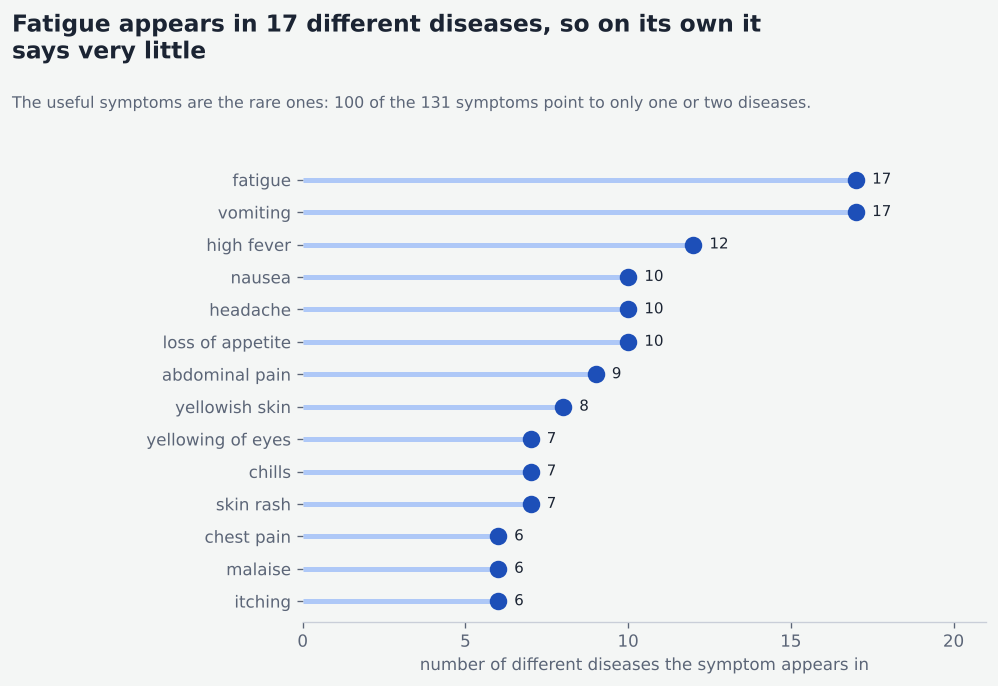

In [6]:
seen = raw.drop_duplicates("case")
dis_per_sym = pd.Series({s: seen[seen.symptoms.map(lambda ss: s in ss)].disease.nunique()
                         for s in set().union(*seen.symptoms)}).sort_values(ascending=False)
top = dis_per_sym.head(14)[::-1]
tell = int((dis_per_sym <= 2).sum())
fig, ax = plt.subplots(figsize=(8.5, 5.6)); fig.subplots_adjust(top=0.76, bottom=0.07, left=0.30, right=0.97)
ax.hlines(top.index, 0, top.values, color=LIGHT, lw=3); ax.scatter(top.values, top.index, s=90, color=COBALT, zorder=3)
for s, v in top.items(): ax.text(v + 0.5, s, str(int(v)), va="center", fontsize=9, color=INK)
ax.set_xlabel("number of different diseases the symptom appears in"); ax.set_xlim(0, top.max() + 4); ax.set_xticks(range(0, int(top.max()) + 4, 5))
ax.set_yticks(range(len(top))); ax.set_yticklabels([s.replace("_", " ") for s in top.index])
story(fig, f"{top.index[-1].replace('_',' ').capitalize()} appears in {int(top.iloc[-1])} different diseases, so on its own it says very little",
      f"The useful symptoms are the rare ones: {tell} of the {len(dis_per_sym)} symptoms point to only one or two diseases.")
plt.show()

## Diseases that look alike

If two diseases share most of their symptoms, no model can reliably separate them from the symptom list alone. The pairs with the most overlap are nearly all liver conditions: Hepatitis D and E share 69% of their symptoms, Hepatitis D and A share 67%, and chronic cholestasis overlaps heavily with several hepatitis types. Keep this chart in mind in chapter 5. These are exactly the diseases where the model makes its mistakes.

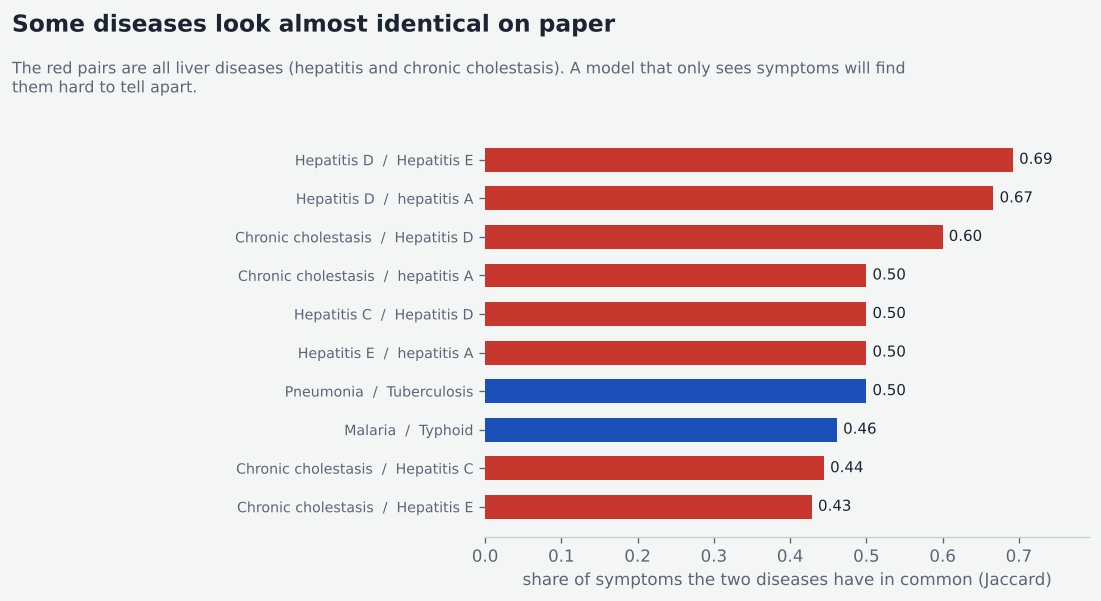

Median overlap between any two diseases: 0.00


In [7]:
diseases = sorted(raw.disease.unique())
dsyms = {d: set().union(*raw[raw.disease == d].symptoms) for d in diseases}
J = pd.DataFrame({b: {a: len(dsyms[a] & dsyms[b]) / len(dsyms[a] | dsyms[b]) for a in diseases} for b in diseases})
pairs = sorted(((a, b, J.loc[a, b]) for i, a in enumerate(diseases) for b in diseases[i+1:]), key=lambda t: -t[2])
top_pairs = pairs[:10][::-1]
fig, ax = plt.subplots(figsize=(9.5, 5)); fig.subplots_adjust(top=0.78, bottom=0.10, left=0.43, right=0.96)
lab = [f"{a}  /  {b}" for a, b, _ in top_pairs]; val = [v for *_, v in top_pairs]
ax.barh(lab, val, color=[RED if ("epatitis" in l or "holestasis" in l) else COBALT for l in lab], height=0.62)
for i, v in enumerate(val): ax.text(v + 0.008, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, max(val) + 0.1); ax.set_xlabel("share of symptoms the two diseases have in common (Jaccard)")
ax.tick_params(axis="y", labelsize=8.5)
story(fig, "Some diseases look almost identical on paper", "The red pairs are all liver diseases (hepatitis and chronic cholestasis). A model that only sees symptoms will find them hard to tell apart.")
plt.show()
print(f"Median overlap between any two diseases: {np.median([p[2] for p in pairs]):.2f}")

# Chapter 2. What care does each condition need?

Every condition in the project is assigned a recommended KEPH level, from 2 (dispensary) to 6 (national referral hospital). **This mapping is a judgement I made for the project. It is not an official clinical rule**, and a clinician might draw it differently. With that said, here is how it comes out: 7 conditions map to level 2, 16 to level 3, 11 to level 4, 5 to level 5 (all liver diseases) and 2 to level 6 (heart attack and paralysis / brain haemorrhage).

In [8]:
keph_map = load_keph_mapping(ROOT / "data" / "disease_keph_mapping.csv")
dmap = pd.Series(keph_map).rename("keph_level")
print("Diseases per recommended KEPH level:"); print(dmap.value_counts().sort_index().to_string())
for lvl in (5, 6): print(f"\nLevel {lvl}:", ", ".join(sorted(dmap[dmap == lvl].index)))
print("\nNote: this disease -> level mapping is a judgement made for this project, not an official clinical rule.")

Diseases per recommended KEPH level:
keph_level
2     7
3    16
4    11
5     5
6     2

Level 5: Alcoholic hepatitis, Chronic cholestasis, Hepatitis B, Hepatitis C, Hepatitis D

Level 6: Heart attack, Paralysis (brain hemorrhage)

Note: this disease -> level mapping is a judgement made for this project, not an official clinical rule.


# Chapter 3. What does Kenya actually have?

## The facility registry

The database has 9,736 facilities in all 47 counties, built from the KMPDC registry with coordinates. Four out of five are level 2 dispensaries and clinics. Only 31 facilities, about 0.3%, are at level 5 or 6.

One caution: many facility levels in the registry were **inferred** from the facility type, not confirmed from an official list. Everything below depends on those levels being roughly right.

In [9]:
con = sqlite3.connect(ROOT / "backend" / "database.sqlite")
fac = pd.read_sql("select * from facilities", con); con.close()
lvl = fac.keph_level.value_counts().sort_index()
print(f"{len(fac):,} facilities across {fac.county.nunique()} counties")
print(pd.DataFrame({"facilities": lvl, "share %": (lvl / lvl.sum() * 100).round(1)}).to_string())

9,736 facilities across 47 counties
            facilities  share %
keph_level                     
2                 7722     79.3
3                 1431     14.7
4                  552      5.7
5                   25      0.3
6                    6      0.1


## Checking the registry before I lean on it

- **Two facilities sit outside the Kenya bounding box I used** (Kibish and Lokamarinyang dispensaries, Turkana, around 5.3 degrees north). They may be real or badly geocoded. I left them out of the distance analysis to be safe.
- **13 rows share a name and a county** with another row. They could be duplicates or different branches, and I have not removed them.
- **All six level 6 facilities are labelled "National Referral Hospital"** in the registry, including privately owned hospitals such as Avenue, Nairobi West and Eldoret Hospital. I have kept the registry's labels, but a reader should know the top of the pyramid depends on them.
- Level 5 is mostly "Provincial General Hospital", and some are privately owned, which is unusual. I kept them as given.

In [10]:
out_box = fac[~fac.latitude.between(-4.8, 5.1) | ~fac.longitude.between(33.8, 41.95)]
print("Coordinates outside Kenya's bounding box:", len(out_box))
print(out_box[["facility_name", "county", "latitude", "longitude"]].to_string(index=False))
print("\nRows sharing the same name and county:", int(fac.duplicated(["facility_name", "county"]).sum()))
print("\nThe", int((fac.keph_level == 6).sum()), "level 6 facilities:")
print(fac[fac.keph_level == 6][["facility_name", "facility_type", "county"]].to_string(index=False))
print("\nAny facility types that look out of place at their level (level 5-6 listed as a plain 'Hospital' type):")
print(fac[fac.keph_level >= 5].facility_type.value_counts().to_string())

Coordinates outside Kenya's bounding box: 2
           facility_name  county  latitude  longitude
       Kibish Dispensary Turkana   5.28609   35.82228
Lokamarinyang Dispensary Turkana   5.30728   35.65440

Rows sharing the same name and county: 13

The 6 level 6 facilities:
                  facility_name              facility_type      county
                Avenue Hospital National Referral Hospital     Nairobi
               Eldoret Hospital National Referral Hospital Uasin Gishu
     Kenyatta National Hospital National Referral Hospital     Nairobi
 Moi Teaching Refferal Hospital National Referral Hospital Uasin Gishu
          Nairobi West Hospital National Referral Hospital     Nairobi
National Spinal Injury Hospital National Referral Hospital     Nairobi

Any facility types that look out of place at their level (level 5-6 listed as a plain 'Hospital' type):
facility_type
Provincial General Hospital          22
National Referral Hospital            6
Regional Blood Transfusion C

## Need against supply

This is the chart the whole project rests on. 44% of the 41 conditions are mapped to level 4 or higher, but only 6% of facilities are level 4 or higher, and 0.3% are level 5 or 6. The system cannot create hospitals. What it can do is stop people from guessing.

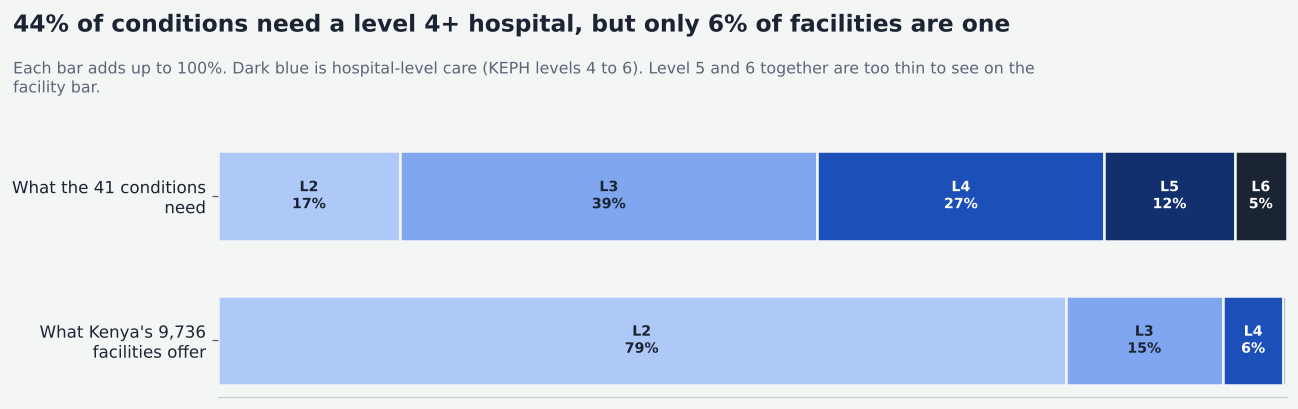

Level 5 and 6 facilities: 31 in total (0.32%).  Conditions mapped to level 5 or 6: 7 of 41.


In [11]:
levels = [2, 3, 4, 5, 6]
need = np.array([(dmap == l).mean() * 100 for l in levels]); supply = np.array([(fac.keph_level == l).mean() * 100 for l in levels])
shade = [LIGHT, "#7FA6EE", COBALT, DEEP, INK]
fig, ax = plt.subplots(figsize=(11, 3.7)); fig.subplots_adjust(top=0.68, bottom=0.10, left=0.17, right=0.98)
for y_, vals, name in [(1, need, "What the 41 conditions\nneed"), (0, supply, "What Kenya's 9,736\nfacilities offer")]:
    left = 0
    for l, v, c in zip(levels, vals, shade):
        ax.barh(y_, v, left=left, color=c, height=0.62, edgecolor=PAPER, lw=1.5)
        if v >= 4: ax.text(left + v / 2, y_, f"L{l}\n{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white" if l >= 4 else INK, fontweight="bold")
        left += v
ax.set_yticks([1, 0]); ax.set_yticklabels(["What the 41 conditions\nneed", "What Kenya's 9,736\nfacilities offer"], fontsize=10, color=INK)
ax.set_xlim(0, 100); ax.set_xticks([]); ax.grid(False)
hn, hs = need[2:].sum(), supply[2:].sum()
story(fig, f"{hn:.0f}% of conditions need a level 4+ hospital, but only {hs:.0f}% of facilities are one",
      "Each bar adds up to 100%. Dark blue is hospital-level care (KEPH levels 4 to 6). Level 5 and 6 together are too thin to see on the facility bar.")
plt.show()
print(f"Level 5 and 6 facilities: {int((fac.keph_level >= 5).sum())} in total ({(fac.keph_level >= 5).mean()*100:.2f}%).  Conditions mapped to level 5 or 6: {int((dmap >= 5).sum())} of {len(dmap)}.")

## Who runs the facilities

Public facilities are strongest at level 3 (58%). At level 2, more than half of the clinics are private or faith-based. At the top, about half of the level 5 and 6 hospitals are private. For a patient this matters, because a private hospital may be near but cost more. The app already lets people filter by ownership for that reason.

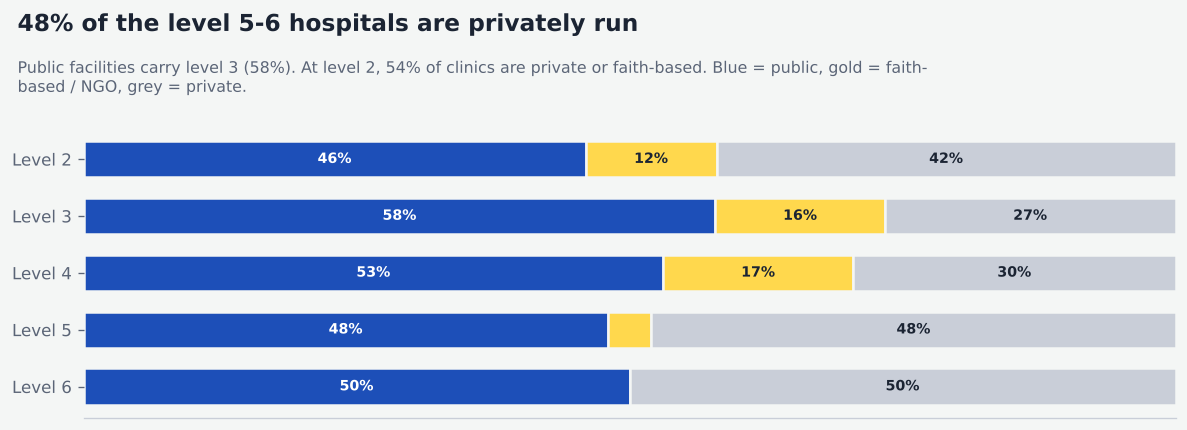

In [12]:
def bucket(o):
    o = str(o).lower()
    if any(k in o for k in ("ministry", "local authority", "state corp", "state coorp", "public")): return "Public"
    if any(k in o for k in ("faith", "catholic", "christian", "non-gov", "ngo", "muslim", "sda")): return "Faith-based / NGO"
    return "Private"
fac["owner_group"] = fac.ownership.map(bucket)
tab = (pd.crosstab(fac.keph_level, fac.owner_group, normalize="index") * 100)[["Public", "Faith-based / NGO", "Private"]]
fig, ax = plt.subplots(figsize=(10, 3.9)); fig.subplots_adjust(top=0.72, bottom=0.10, left=0.07, right=0.98)
left = np.zeros(len(tab))
for col, c in zip(tab.columns, [COBALT, GOLD, GREY]):
    ax.barh([f"Level {i}" for i in tab.index], tab[col], left=left, color=c, height=0.64, edgecolor=PAPER, lw=1.5)
    for i, (l, v) in enumerate(zip(left, tab[col])):
        if v > 7: ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white" if c == COBALT else INK, fontweight="bold")
    left += tab[col].values
ax.invert_yaxis(); ax.set_xticks([]); ax.set_xlim(0, 100)
hi = fac[fac.keph_level >= 5]
priv_hi = (hi.owner_group == "Private").mean() * 100
story(fig, f"{priv_hi:.0f}% of the level 5-6 hospitals are privately run",
      f"Public facilities carry level 3 ({tab.loc[3, 'Public']:.0f}%). At level 2, {100 - tab.loc[2, 'Public']:.0f}% of clinics are private or faith-based. Blue = public, gold = faith-based / NGO, grey = private.")
plt.show()

# Chapter 4. The access gap

## County by county

Counting facilities at level 4 or above shows a steep drop from Nairobi (48) to the counties at the bottom of the chart. **31 of the 47 counties have no level 5 or 6 hospital at all.** Seven counties have five or fewer level 4+ facilities, and Tana River, Isiolo and Samburu have two or three. For someone in a red county, a serious case means travelling to another county.

This chart counts facilities, not people. I have no population data in the project, so I cannot say which county is worst *per person*.

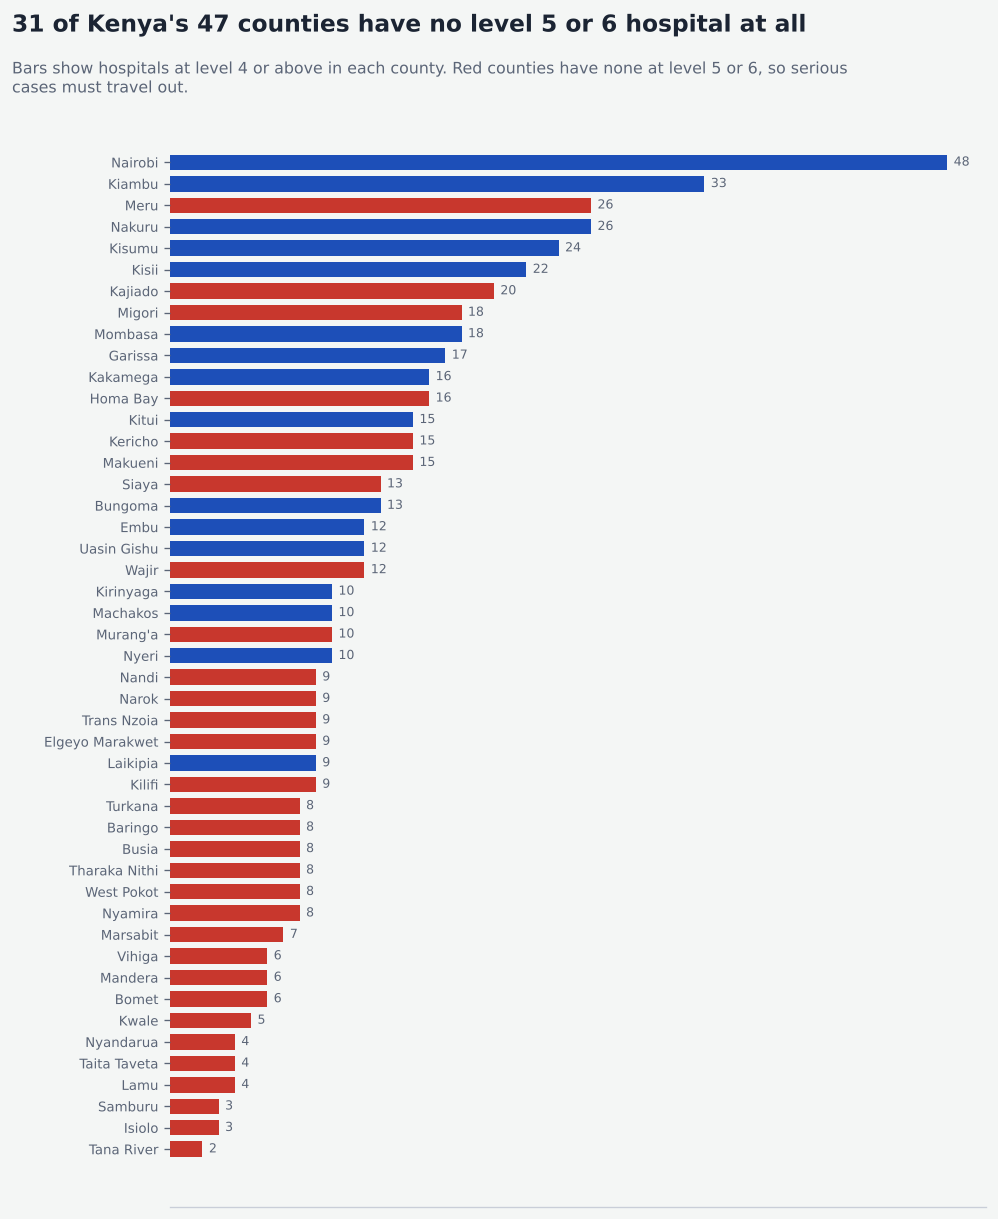

Counties with five or fewer level 4+ facilities: 7


In [13]:
by_county = fac.groupby("county").agg(total=("facility_id", "size"),
                                      l4plus=("keph_level", lambda s: int((s >= 4).sum())),
                                      l5plus=("keph_level", lambda s: int((s >= 5).sum()))).sort_values("l4plus")
no5 = int((by_county.l5plus == 0).sum())
fig, ax = plt.subplots(figsize=(8.5, 10.5)); fig.subplots_adjust(top=0.915, bottom=0.04, left=0.17, right=0.97)
ax.barh(by_county.index, by_county.l4plus, color=[RED if v == 0 else COBALT for v in by_county.l5plus], height=0.72)
for i, v in enumerate(by_county.l4plus): ax.text(v + 0.4, i, str(v), va="center", fontsize=7.5, color=SOFT)
ax.tick_params(axis="y", labelsize=8); ax.set_xticks([])
story(fig, f"{no5} of Kenya's 47 counties have no level 5 or 6 hospital at all",
      "Bars show hospitals at level 4 or above in each county. Red counties have none at level 5 or 6, so serious cases must travel out.")
plt.show()
print("Counties with five or fewer level 4+ facilities:", int((by_county.l4plus <= 5).sum()))

## How far is the nearest hospital?

For every level 2 or 3 facility I measured the straight-line distance to the nearest level 4+ hospital and the nearest level 5+ hospital. The answer depends heavily on which level you need:

- **Level 4+:** the median is 5.5 km and only 1.8% of facilities are more than 50 km away. Level 4 care is close for most.
- **Level 5+:** the median is 31.6 km, a third of facilities are more than 50 km away and **12.7% are more than 100 km away**.

So the real access gap is not at the middle of the health system. It sits at the very top, with only 31 facilities for the whole country. These are straight-line distances, so real road distances will be longer.

In [14]:
R = 6371.0
def nearest_km(src_lat, src_lon, dst_lat, dst_lon, chunk=800):
    out = np.empty(len(src_lat)); dl, dn = np.radians(dst_lat), np.radians(dst_lon)
    for i in range(0, len(src_lat), chunk):
        sl, sn = np.radians(src_lat[i:i+chunk])[:, None], np.radians(src_lon[i:i+chunk])[:, None]
        a = np.sin((dl - sl) / 2) ** 2 + np.cos(sl) * np.cos(dl) * np.sin((dn - sn) / 2) ** 2
        out[i:i+chunk] = (2 * R * np.arcsin(np.sqrt(a))).min(axis=1)
    return out

clean = fac[fac.latitude.between(-4.8, 5.1) & fac.longitude.between(33.8, 41.95)].copy()
small = clean[clean.keph_level <= 3]
for lo in (4, 5):
    dst = clean[clean.keph_level >= lo]
    clean.loc[small.index, f"dist_to_l{lo}"] = nearest_km(small.latitude.values, small.longitude.values, dst.latitude.values, dst.longitude.values)
d4, d5 = clean.loc[small.index, "dist_to_l4"], clean.loc[small.index, "dist_to_l5"]
print("Straight-line distance from each level 2-3 facility to the nearest higher-level facility (km):")
print(pd.DataFrame({"to level 4+": d4.describe(percentiles=[.5, .9]), "to level 5+": d5.describe(percentiles=[.5, .9])}).round(1).loc[["mean", "50%", "90%", "max"]].to_string())
for lim in (25, 50, 100): print(f"  more than {lim:3d} km from a level 4+ hospital: {(d4 > lim).mean()*100:5.1f}%   from a level 5+ hospital: {(d5 > lim).mean()*100:5.1f}%")

Straight-line distance from each level 2-3 facility to the nearest higher-level facility (km):
      to level 4+  to level 5+
mean          8.8         55.7
50%           5.5         31.6
90%          20.3        117.9
max         119.6        550.0
  more than  25 km from a level 4+ hospital:   7.2%   from a level 5+ hospital:  57.9%
  more than  50 km from a level 4+ hospital:   1.8%   from a level 5+ hospital:  33.8%
  more than 100 km from a level 4+ hospital:   0.0%   from a level 5+ hospital:  12.7%


## The gap on a map

I did not use a map library. Each dot is a clinic placed at its coordinates, and the dots draw Kenya's shape themselves. The yellow areas around Nairobi, Nakuru, Eldoret, Kisumu and Mombasa are close to a referral hospital. The dark red north and east are not. This is the picture that motivated the project.

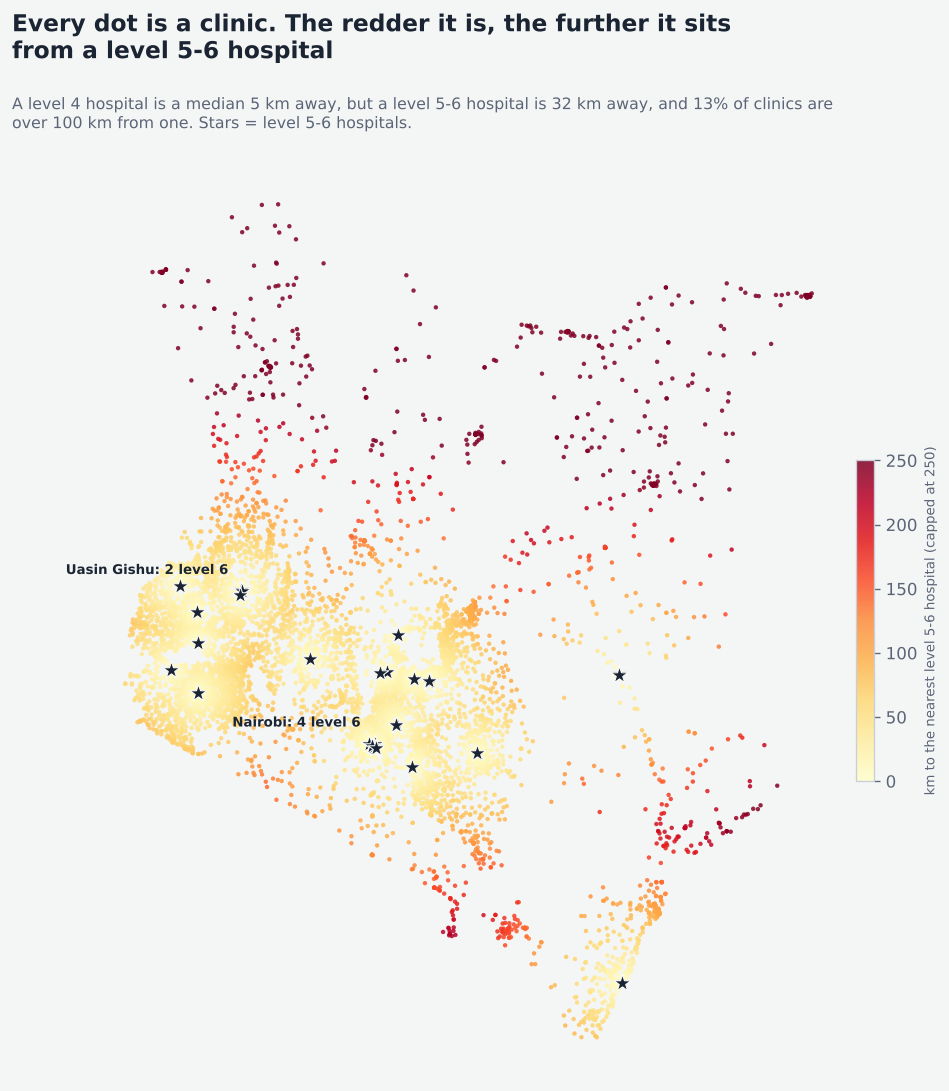

In [15]:
fig, ax = plt.subplots(figsize=(8.6, 9.2)); fig.subplots_adjust(top=0.85, bottom=0.02, left=0.0, right=0.98)
sc = ax.scatter(small.longitude, small.latitude, c=d5.clip(upper=250), cmap="YlOrRd", s=7, alpha=0.85, linewidths=0)
big = clean[clean.keph_level >= 5]
ax.scatter(big.longitude, big.latitude, marker="*", s=110, color=INK, edgecolor="white", lw=0.6, zorder=5)
for name_, c_ in clean[clean.keph_level == 6].groupby("county"):
    ax.annotate(f"{name_}: {len(c_)} level 6", (c_.longitude.mean(), c_.latitude.mean()), xytext=(-8, 12) if name_ == "Nairobi" else (-8, 10), textcoords="offset points", ha="right", fontsize=8, color=INK, fontweight="bold")
ax.set_aspect(1 / np.cos(np.radians(0.5))); ax.axis("off")
cb = fig.colorbar(sc, ax=ax, shrink=0.35, pad=0.01, aspect=18); cb.set_label("km to the nearest level 5-6 hospital (capped at 250)", fontsize=8)
story(fig, "Every dot is a clinic. The redder it is, the further it sits from a level 5-6 hospital",
      f"A level 4 hospital is a median {d4.median():.0f} km away, but a level 5-6 hospital is {d5.median():.0f} km away, and {(d5 > 100).mean()*100:.0f}% of clinics are over 100 km from one. Stars = level 5-6 hospitals.")
plt.show()

## The longest journeys

The counties where a typical level 2-3 clinic is furthest from a level 5-6 hospital are Mandera (about 530 km), Marsabit (362), Turkana (291), Wajir (249) and Lamu (222). Notice that these counties are not far from a *level 4* hospital: Mandera's median is 5.5 km. The system's job there is not to find the nearest hospital, it is to say honestly when the right care is far away so people can plan the trip early.

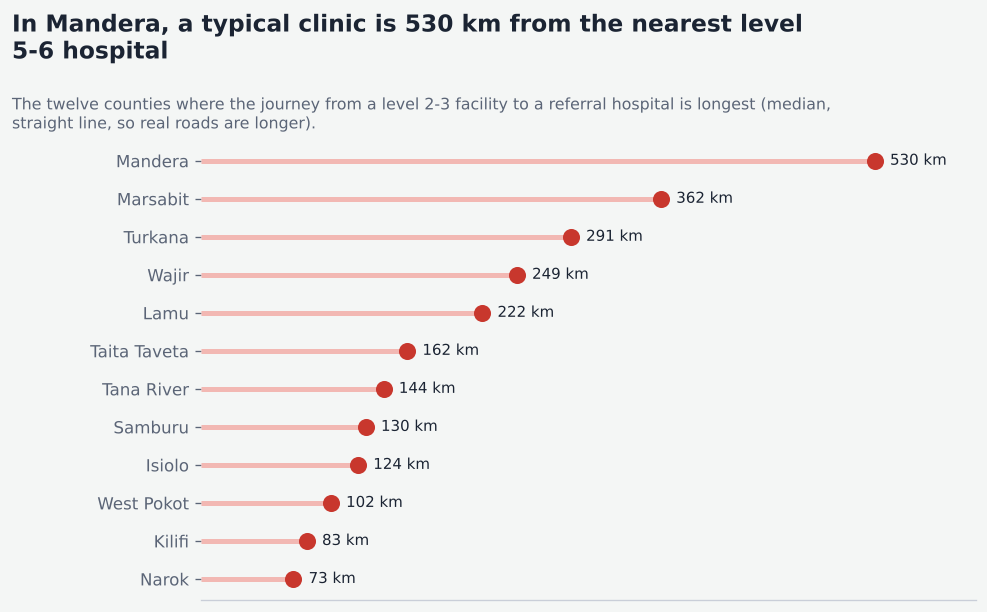

                n  median_to_l4  median_to_l5
county                                       
Mandera        78           5.5         530.4
Marsabit      104          10.8         362.2
Turkana       153          29.4         291.2
Wajir         139          16.4         248.7
Lamu           41          12.1         221.5
Taita Taveta   77          11.5         162.4
Tana River     56          23.7         143.9
Samburu        90          26.6         129.9
Isiolo         49          23.4         123.8
West Pokot    118          11.6         102.4
Kilifi        242          10.6          83.4
Narok         159          15.6          72.9


In [16]:
cm = clean.loc[small.index].groupby("county").agg(n=("facility_id", "size"), median_to_l4=("dist_to_l4", "median"), median_to_l5=("dist_to_l5", "median"))
w = cm.sort_values("median_to_l5", ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.4)); fig.subplots_adjust(top=0.78, bottom=0.07, left=0.20, right=0.96)
ax.hlines(w.index, 0, w.median_to_l5, color="#F2B8B3", lw=3); ax.scatter(w.median_to_l5, w.index, color=RED, s=85, zorder=3)
for c_, v in w.median_to_l5.items(): ax.text(v + 12, c_, f"{v:.0f} km", va="center", fontsize=9)
ax.set_xlim(0, w.median_to_l5.max() * 1.15); ax.set_xticks([])
story(fig, f"In {w.index[-1]}, a typical clinic is {w.median_to_l5.iloc[-1]:.0f} km from the nearest level 5-6 hospital",
      "The twelve counties where the journey from a level 2-3 facility to a referral hospital is longest (median, straight line, so real roads are longer).")
plt.show()
print(cm.sort_values("median_to_l5", ascending=False).head(12).round(1).to_string())

# Chapter 5. Can we trust the model?

I retrain a Logistic Regression with exactly the settings of the deployed model on the project's standard 80/20 split, and it reproduces the 92.44% shown in the web app. **That number comes from a random split of the augmented data**, where rows made from the same real case can sit on both sides, so I treat it as optimistic.

In [17]:
from sklearn.base import clone
deployed = joblib.load(ROOT / "ML" / "disease_classifier.joblib")
features = joblib.load(ROOT / "ML" / "symptom_features.joblib")
X, y = vectorize(aug_rows, features)
Xtr, Xte, ytr, yte = manual_train_test_split(X, y)          # the project's standard 80/20 split
clf = clone(deployed).fit(Xtr, ytr)                           # same settings as the deployed model, trained on the 80%
pred = clf.predict(Xte)
shown = json.load(open(ROOT / "ML" / "evaluation" / "metrics.json"))["accuracy"]["test"]
print("Model:", type(clf).__name__, "| held-out test rows:", len(yte))
print(f"Disease-level accuracy on the held-out test split: {(pred == yte).mean()*100:.2f}%   (the web app reports {shown*100:.2f}%)")
print("Caution: rows made from the same real case can land on both sides of this random split, so this is probably optimistic.")

Model: LogisticRegression | held-out test rows: 1230
Disease-level accuracy on the held-out test split: 92.44%   (the web app reports 92.44%)
Caution: rows made from the same real case can land on both sides of this random split, so this is probably optimistic.


## Does the score depend on how I split the data?

I repeated the evaluation with 10 different seeds for two kinds of split: a plain random split of rows, and a split by *exact case*, where identical rows are kept together. The two come out the same, about 92.5%, with a spread of under one point.

I expected the case-grouped split to be harder, and it is not. The reason is how the augmented data is built: each augmented row is a *noisy variant* of one of the 304 real cases, so it no longer matches its source exactly and the exact-case grouping cannot keep them together. Near-copies of a case can still appear in both training and test. So the stable score is reassuring about seeds but says nothing either way about leakage, which is why I keep calling 92.4% probably optimistic. A proper fix would be to tag each augmented row with its source case and split on that, which the current data generator does not record.

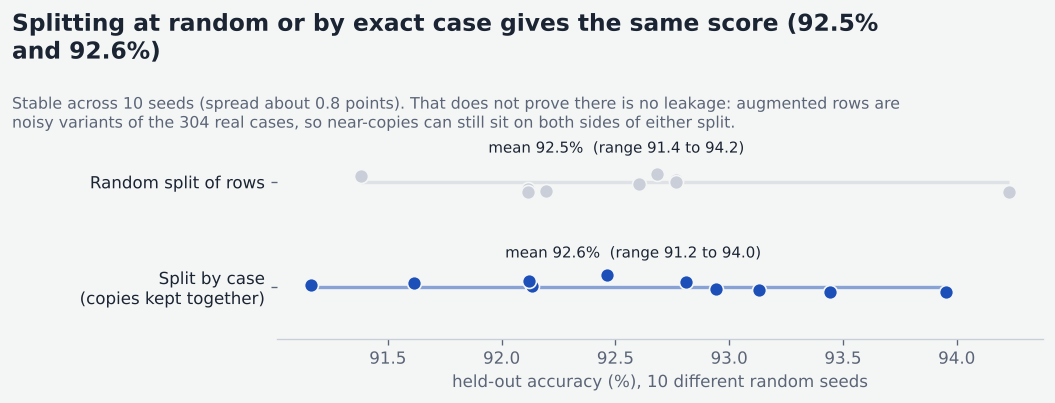

Random split: mean 92.50%, std 0.70.  Case-grouped split: mean 92.58%, std 0.81.


In [18]:
from train_model import build_case_groups, group_train_test_split
groups = build_case_groups(aug_rows)
seeds = range(10)
rand_acc, group_acc = [], []
for sd in seeds:
    a, b, c, d = manual_train_test_split(X, y, seed=sd)
    rand_acc.append((clone(deployed).fit(a, c).predict(b) == d).mean() * 100)
    a, b, c, d = group_train_test_split(X, y, groups, seed=sd)
    group_acc.append((clone(deployed).fit(a, c).predict(b) == d).mean() * 100)

fig, ax = plt.subplots(figsize=(9, 3.4)); fig.subplots_adjust(top=0.70, bottom=0.16, left=0.26, right=0.97)
rng = np.random.default_rng(3)
for yy, vals, col, lab in [(1, rand_acc, GREY, "Random split of rows"), (0, group_acc, COBALT, "Split by case\n(copies kept together)")]:
    ax.scatter(vals, yy + rng.uniform(-.12, .12, len(vals)), s=70, color=col, edgecolor=PAPER, zorder=3)
    ax.hlines(yy, min(vals), max(vals), color=col, lw=2, alpha=.5)
    ax.text(np.mean(vals), yy + 0.28, f"mean {np.mean(vals):.1f}%  (range {min(vals):.1f} to {max(vals):.1f})", ha="center", fontsize=9, color=INK)
ax.set_yticks([1, 0]); ax.set_yticklabels(["Random split of rows", "Split by case\n(copies kept together)"], color=INK)
ax.set_ylim(-0.5, 1.6); ax.set_xlabel("held-out accuracy (%), 10 different random seeds")
story(fig, f"Splitting at random or by exact case gives the same score ({np.mean(rand_acc):.1f}% and {np.mean(group_acc):.1f}%)",
      f"Stable across 10 seeds (spread about {max(np.std(rand_acc), np.std(group_acc)):.1f} points). That does not prove there is no leakage: augmented rows are noisy variants of the 304 real cases, so near-copies can still sit on both sides of either split.")
plt.show()
print(f"Random split: mean {np.mean(rand_acc):.2f}%, std {np.std(rand_acc):.2f}.  Case-grouped split: mean {np.mean(group_acc):.2f}%, std {np.std(group_acc):.2f}.")

## Where does it struggle?

The model is perfect on 5 of 41 conditions. The weakest are Hepatitis D (F1 0.69) and Hepatitis C (0.78), followed by pneumonia, malaria, chronic cholestasis and hypoglycaemia. The hepatitis family from chapter 1 shows up exactly where we expected it.

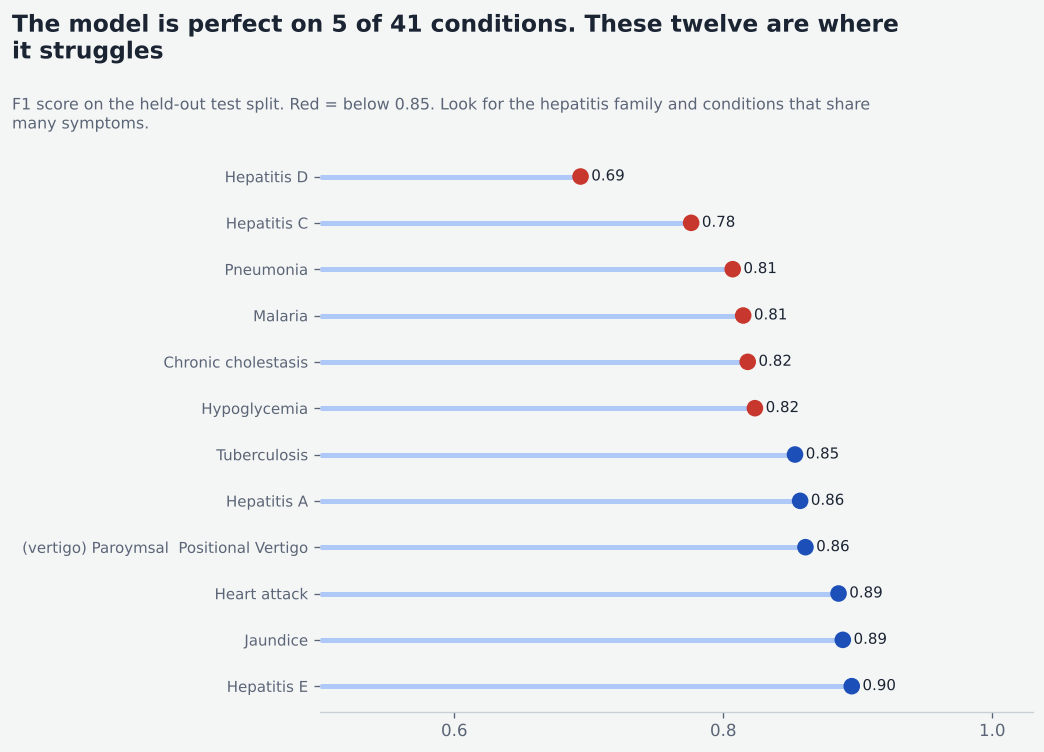

In [19]:
from sklearn.metrics import precision_recall_fscore_support
labels = sorted(set(yte))
p, r, f1, sup = precision_recall_fscore_support(yte, pred, labels=labels, zero_division=0)
pdx = pd.DataFrame({"f1": f1, "support": sup}, index=labels).sort_values("f1")
n_perfect = int((pdx.f1 > 0.999).sum())
fig, ax = plt.subplots(figsize=(9, 6.4)); fig.subplots_adjust(top=0.80, bottom=0.07, left=0.30, right=0.96)
low = pdx.head(12)[::-1]
ax.hlines([cap(i) for i in low.index], 0.5, low.f1, color=LIGHT, lw=3); ax.scatter(low.f1, [cap(i) for i in low.index], color=[RED if v < 0.85 else COBALT for v in low.f1], s=80, zorder=3)
for c_, v in low.f1.items(): ax.text(v + 0.008, cap(c_), f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0.5, 1.03); ax.set_xticks([0.6, 0.8, 1.0]); ax.tick_params(axis="y", labelsize=9)
story(fig, f"The model is perfect on {n_perfect} of {len(pdx)} conditions. These twelve are where it struggles",
      "F1 score on the held-out test split. Red = below 0.85. Look for the hepatitis family and conditions that share many symptoms.")
plt.show()

## The actual mistakes

The most common error is Hepatitis A predicted as Hepatitis D (5 times), followed by Hepatitis E as Hepatitis D (3 times). Their symptom lists overlap by about two thirds. Some mistakes do not change the advice at all: gastroenteritis predicted as malaria both map to the same care level.

In [20]:
conf = Counter((t, q) for t, q in zip(yte, pred) if t != q)
print("Most common mistakes (true condition -> predicted condition):")
for (t, q), n in conf.most_common(10):
    sim = J.loc[t, q] if t in J.index and q in J.index else float("nan")
    note = "same care level, so the advice would not change" if keph_map[t] == keph_map[q] else f"care level changes: {keph_map[t]} -> {keph_map[q]}"
    print(f"  {n:2d}x  {t}  ->  {q}   (symptom overlap {sim:.2f}; {note})")

Most common mistakes (true condition -> predicted condition):
   5x  hepatitis A  ->  Hepatitis D   (symptom overlap 0.67; care level changes: 3 -> 5)
   3x  Hepatitis E  ->  Hepatitis D   (symptom overlap 0.69; care level changes: 4 -> 5)
   3x  Gastroenteritis  ->  Malaria   (symptom overlap 0.20; same care level, so the advice would not change)
   2x  Chronic cholestasis  ->  Hepatitis C   (symptom overlap 0.44; same care level, so the advice would not change)
   2x  Bronchial Asthma  ->  Pneumonia   (symptom overlap 0.31; care level changes: 3 -> 4)
   2x  Tuberculosis  ->  Heart attack   (symptom overlap 0.25; care level changes: 4 -> 6)
   2x  Hypoglycemia  ->  Migraine   (symptom overlap 0.24; care level changes: 4 -> 3)
   2x  Tuberculosis  ->  Pneumonia   (symptom overlap 0.50; same care level, so the advice would not change)
   2x  Pneumonia  ->  Dengue   (symptom overlap 0.19; same care level, so the advice would not change)
   2x  Jaundice  ->  Chronic cholestasis   (sympto

## What actually matters: the wrong care level

A wrong disease only matters if it changes where the person is sent. Of the 1,230 test cases, 7.6% get the wrong disease, but only 5.0% get the wrong care level, because a third of the disease mistakes still land on the right level.

Within the wrong care levels there are two kinds. **Sent too high (3.1%)** wastes a trip and a referral, which is the lesser harm. **Sent too low (2.0%)** is the dangerous one, because a patient who needs a hospital is told a clinic is enough. An example of under-triage in the mistake list above is Hypoglycaemia predicted as migraine (level 4 down to 3). The red-flag rules in the app are there to catch the worst cases independently of the model, but they cover only a handful of emergencies, so this 2% should not be called solved.

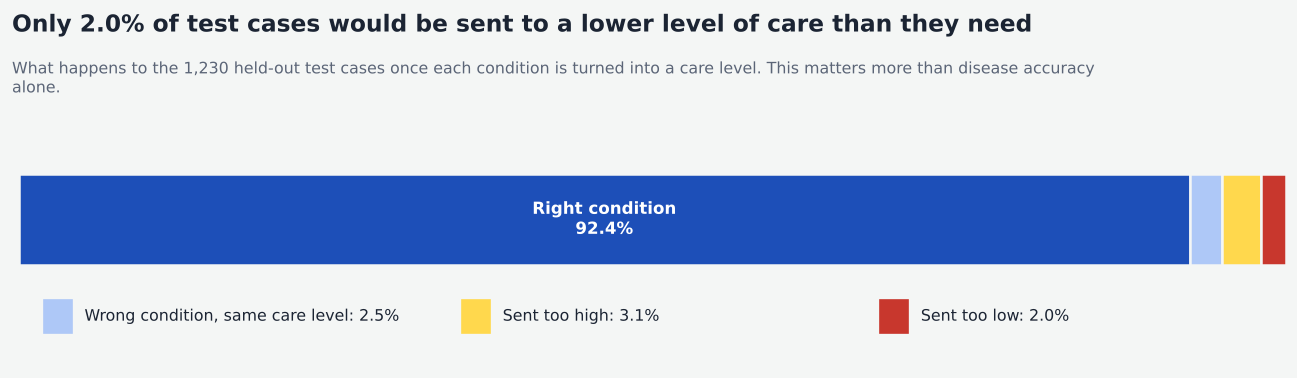

recommended level    2    3    4    5   6
true level                               
2                  198    4    2    0   2
3                    2  462    3    9   2
4                    5   11  322   12   4
5                    0    2    1  132   0
6                    0    1    1    1  54

Wrong condition: 93 of 1230 (7.6%).  Wrong care level: 62 (5.0%).
Of the wrong-condition cases, 31 (33%) still land on the right care level.


In [21]:
true_lvl = np.array([keph_map[d] for d in yte]); pred_lvl = np.array([keph_map[d] for d in pred])
n = len(yte)
right = int((pred == yte).sum())
wrong_same = int(((pred != yte) & (pred_lvl == true_lvl)).sum())
under = int((pred_lvl < true_lvl).sum()); over = int((pred_lvl > true_lvl).sum())
parts = [("Right condition", right, COBALT), ("Wrong condition, same care level", wrong_same, LIGHT),
         ("Sent too high", over, GOLD), ("Sent too low", under, RED)]
fig, ax = plt.subplots(figsize=(11, 3.2)); fig.subplots_adjust(top=0.66, bottom=0.04, left=0.02, right=0.98)
left = 0
for name, v, c in parts:
    ax.barh(0, v / n * 100, left=left, color=c, height=0.5, edgecolor=PAPER, lw=1.5)
    if v / n > 0.5: ax.text(left + (v / n * 100) / 2, 0, f"{name}\n{v/n*100:.1f}%", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
    left += v / n * 100
# the small slices get a key underneath, so nothing overlaps
for k, (name, v, c) in enumerate(parts[1:]):
    x0 = 2 + k * 33
    ax.add_patch(Rectangle((x0, -0.62), 2.2, 0.18, color=c, transform=ax.transData, clip_on=False))
    ax.text(x0 + 3.2, -0.53, f"{name}: {v/n*100:.1f}%", va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, 100); ax.set_ylim(-0.8, 0.5); ax.axis("off")
story(fig, f"Only {under/n*100:.1f}% of test cases would be sent to a lower level of care than they need",
      f"What happens to the {n:,} held-out test cases once each condition is turned into a care level. This matters more than disease accuracy alone.")
plt.show()

M = pd.crosstab(pd.Series(true_lvl, name="true level"), pd.Series(pred_lvl, name="recommended level")).reindex(index=[2,3,4,5,6], columns=[2,3,4,5,6], fill_value=0)
print(M.to_string())
print(f"\nWrong condition: {(pred != yte).sum()} of {n} ({(pred != yte).mean()*100:.1f}%).  Wrong care level: {(pred_lvl != true_lvl).sum()} ({(pred_lvl != true_lvl).mean()*100:.1f}%).")
print(f"Of the wrong-condition cases, {wrong_same} ({wrong_same/max((pred != yte).sum(),1)*100:.0f}%) still land on the right care level.")

## Why Logistic Regression

On the same cross-validation, Logistic Regression scored 92.4% against 89.3% for both Gradient Boosting and Random Forest, a gap of about 3 points when the fold-to-fold spread is about 0.6. It is also the fastest to train (3.4 seconds against 164 for Gradient Boosting) and its weights can be read, which helps in explaining the result.

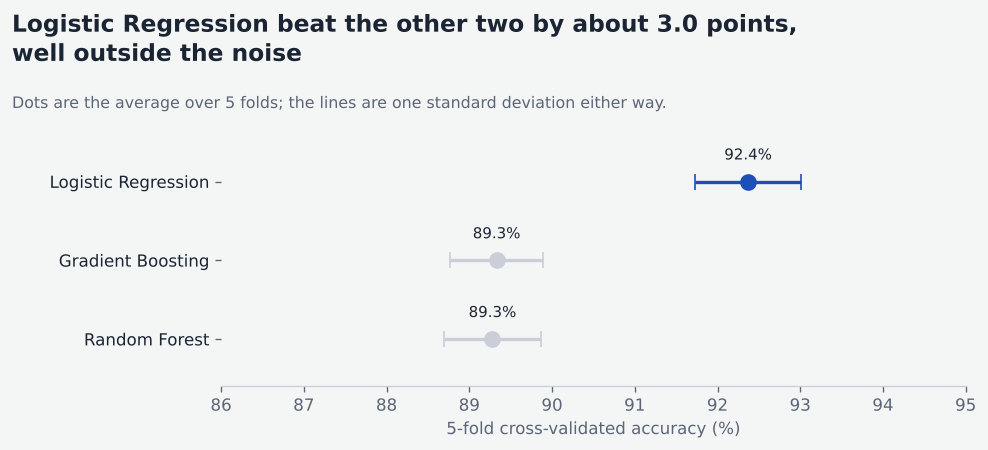

In [22]:
cmp_ = json.load(open(ROOT / "ML" / "evaluation" / "model_comparison.json"))
ms = cmp_["models_compared"]; names = [m["model"] for m in ms]
means = np.array([m["cv_accuracy_mean"] * 100 for m in ms]); stds = np.array([m["cv_accuracy_std"] * 100 for m in ms])
order = np.argsort(means)
fig, ax = plt.subplots(figsize=(8.5, 3.6)); fig.subplots_adjust(top=0.72, bottom=0.10, left=0.22, right=0.95)
for i, k in enumerate(order):
    c = COBALT if names[k] == cmp_["selected_model"] else GREY
    ax.errorbar(means[k], i, xerr=stds[k], fmt="o", color=c, ecolor=c, capsize=5, ms=9, lw=2)
    ax.text(means[k], i + 0.28, f"{means[k]:.1f}%", ha="center", fontsize=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels([names[k] for k in order], fontsize=10, color=INK); ax.set_xlim(86, 95); ax.set_ylim(-0.6, len(order) - 0.2)
ax.set_xlabel("5-fold cross-validated accuracy (%)")
gap = means.max() - np.sort(means)[-2]
story(fig, f"{cmp_['selected_model']} beat the other two by about {gap:.1f} points, well outside the noise",
      "Dots are the average over 5 folds; the lines are one standard deviation either way.")
plt.show()

## Did I leave accuracy on the table?

The main comparison used default settings, so I ran a small extra search: Logistic Regression with the regularisation strength from 0.1 to 100, Naive Bayes, SVM, k-NN, a small neural network, tree ensembles and XGBoost. The best was Multinomial Naive Bayes at 92.4%, only 0.1 points above Logistic Regression's 92.2%, well inside the normal spread. Logistic Regression's own default (C = 1) was the best of its settings. This was **not** a full grid search, and the scores still come from augmented data, so I kept the default model.

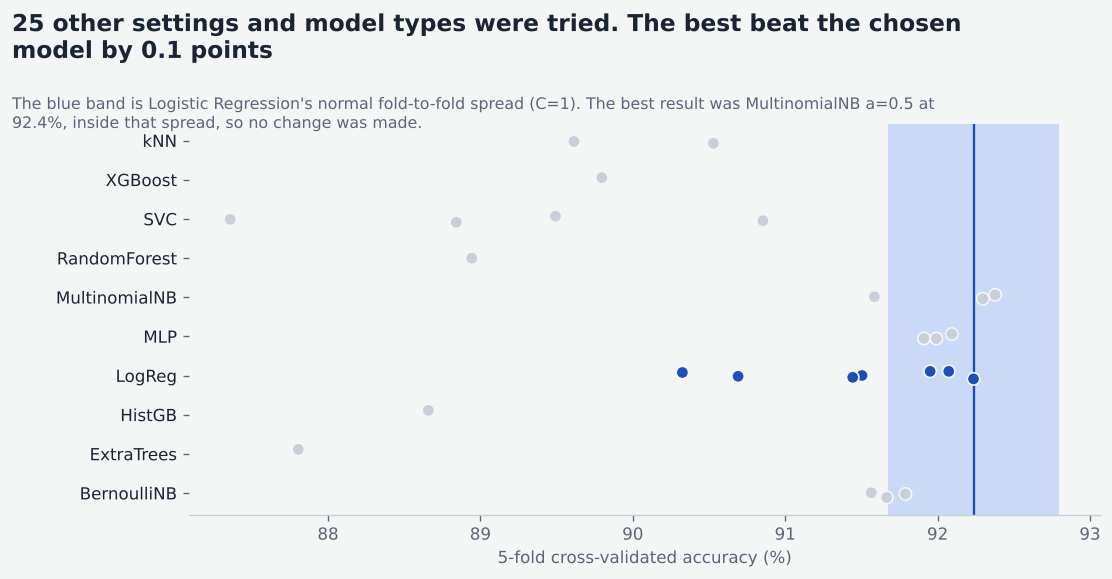

  92.38% +/- 0.44   MultinomialNB a=0.5
  92.30% +/- 0.44   MultinomialNB a=1.0
  92.24% +/- 0.56   LogReg C=1
  92.09% +/- 0.68   MLP a=0.01
  92.07% +/- 0.26   LogReg C=3
  91.99% +/- 0.69   MLP a=0.001
  91.95% +/- 0.58   LogReg C=0.3
  91.91% +/- 0.70   MLP a=0.1


In [23]:
sp = ROOT / "ML" / "extended_search" / "search_results.json"
if sp.exists():
    sr = pd.DataFrame(json.load(open(sp)))
    sr["family"] = sr.model.str.extract(r"^([A-Za-z]+)")[0]
    lr_ref = sr[sr.model == "LogReg C=1"].iloc[0]
    fam = {f: i for i, f in enumerate(sorted(sr.family.unique()))}
    fig, ax = plt.subplots(figsize=(9.5, 4.8)); fig.subplots_adjust(top=0.78, bottom=0.10, left=0.17, right=0.97)
    ax.axvspan((lr_ref.cv_mean - lr_ref.cv_std) * 100, (lr_ref.cv_mean + lr_ref.cv_std) * 100, color=LIGHT, alpha=0.6, lw=0)
    ax.axvline(lr_ref.cv_mean * 100, color=COBALT, lw=1.4)
    ax.scatter(sr.cv_mean * 100, sr.family.map(fam) + np.random.default_rng(1).uniform(-.12, .12, len(sr)), s=55, color=[COBALT if m.startswith("LogReg") else GREY for m in sr.model], zorder=3, edgecolor=PAPER)
    ax.set_yticks(list(fam.values())); ax.set_yticklabels(list(fam.keys()), color=INK); ax.set_xlabel("5-fold cross-validated accuracy (%)")
    best = sr.sort_values("cv_mean").iloc[-1]
    story(fig, f"{len(sr) - 1} other settings and model types were tried. The best beat the chosen model by {(best.cv_mean-lr_ref.cv_mean)*100:.1f} points",
          f"The blue band is Logistic Regression's normal fold-to-fold spread (C=1). The best result was {best.model} at {best.cv_mean*100:.1f}%, inside that spread, so no change was made.")
    plt.show()
    for _, r_ in sr.sort_values("cv_mean", ascending=False).head(8).iterrows(): print(f"  {r_.cv_mean*100:5.2f}% +/- {r_.cv_std*100:.2f}   {r_.model}")
else:
    print("ML/extended_search/search_results.json not found, skipping this chart.")

## A reassuring chart I do not fully trust

On the raw Kaggle data, even when half of each patient's symptoms are dropped or replaced, accuracy stays near 99%. That sounds like robustness, but it mostly proves that the raw data is too easy: each disease has its own tidy symptom pattern, which real patients do not. It is the reason the training set was augmented, and the reason I do not quote 99% anywhere as the system's accuracy.

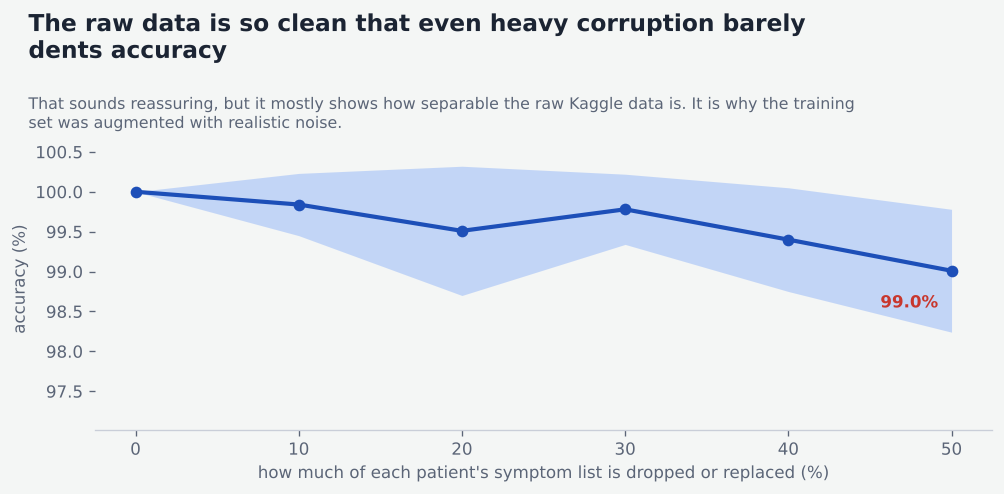

In [24]:
rob = json.load(open(ROOT / "ML" / "evaluation" / "robustness_metrics.json"))
sw = pd.DataFrame(rob["noise_sweep"])
fig, ax = plt.subplots(figsize=(8.5, 4.2)); fig.subplots_adjust(top=0.74, bottom=0.14, left=0.08, right=0.96)
x_ = sw.noise_level * 100; m_ = sw.mean_accuracy * 100; s_ = sw.std_accuracy * 100
ax.fill_between(x_, m_ - s_, m_ + s_, color=LIGHT, alpha=0.7, lw=0); ax.plot(x_, m_, color=COBALT, lw=2.5, marker="o")
ax.set_ylim(min(m_) - 2, 100.8); ax.set_xlabel("how much of each patient's symptom list is dropped or replaced (%)"); ax.set_ylabel("accuracy (%)")
ax.annotate(f"{m_.iloc[-1]:.1f}%", (x_.iloc[-1], m_.iloc[-1]), xytext=(-8, -22), textcoords="offset points", ha="right", color=RED, fontweight="bold")
story(fig, "The raw data is so clean that even heavy corruption barely dents accuracy",
      "That sounds reassuring, but it mostly shows how separable the raw Kaggle data is. It is why the training set was augmented with realistic noise.")
plt.show()

# Chapter 6. What it all means

## What I found

1. **The raw dataset is 304 cases repeated 16 times.** Any accuracy near 100% on it is a memorisation score. I report the augmented-data cross-validation figure (92.4%) instead, and I say it is probably optimistic.
2. **The gap in Kenya's health system is at the top.** Level 4 hospitals are close for most facilities (median 5.5 km), but level 5-6 hospitals are a median 32 km away, 12.7% of clinics are over 100 km from one, and 31 of 47 counties have none.
3. **44% of the conditions need level 4+ care but only 6% of facilities offer it.** This is why a triage tool that names the *level* of care matters more than one that names the disease.
4. **The model's weak spots are the liver diseases that genuinely look alike.** That is a limit of symptom data, not something more tuning would fix.
5. **5.0% of test cases would get the wrong care level, and 2.0% would be sent too low.** That is the number to watch, and it is why the red-flag rules exist.

## What this analysis cannot say

- It is built on a curated, partly synthetic dataset. **It has not been tested on real patients** and is not a clinical tool.
- The KEPH mapping for conditions is my own judgement, and many facility levels were inferred.
- Distances are straight lines, and there is no population or road-quality data, so I cannot rank counties per person or per travel hour.
- The 92.4% comes from a random split of augmented data and is probably optimistic. The case-level 2.0% under-triage figure inherits that.
- There was no significance test between models.

## What I would do next

Test the model on real symptom reports (with ethical approval), add population data to measure access per person, use road distances for the whole country instead of straight lines, and ask a clinician to review the condition-to-level mapping.